In [1]:
import xarray as xr
import glob
import pathlib
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import matplotlib as mpl
import matplotlib.image as mpimg
import os
import my_library
import plot_helpers as plotting
import pandas as pd
import datetime
import global3d_track as g3d

In [2]:
# -- data
# results_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_noec/tropics/20210701')
results_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics')

# -- version
# view_type = 'contiguous' # choses a colormap to highlight where contiguos
view_type = 'differences' # emphasises where continuous

# -- destination
paperdir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/figures/paper')
paperdir.mkdir(parents=1, exist_ok=1)

dpi = 100
ext = 'pdf'

In [3]:
ds = xr.open_mfdataset(results_dir.glob('*/*system_tracks_linked.nc')).isel(time=slice(0,None))
ds = ds.where(ds>0)

In [4]:
def make_repeated_tab20_colorbar(x):
    base = plt.get_cmap("tab20").colors
    colors = [base[i % len(base)] for i in range(x)]
    cmap = mpl.colors.ListedColormap(colors, name=f"repeated_tab20_{x}")
    norm = mpl.colors.BoundaryNorm(np.arange(-0.5, x + 0.5, 1), cmap.N)
    return cmap

In [5]:
di = {"amazon": (-83, -43, -15, 15),
      "congo": (1, 41, -15, 15),
      "mod_congo": (-9, 41, -15, 15),
      "warm_pool": (90, 160, -15, 15),
      "tcr_amazon": (280, 325, -15, 10),
      "tcr_congo": (0, 35, -12, 24),
      "tcr_warm pool": (90, 160, -15, 15),}

In [6]:
ice = ds.system
congo_ice = ice.sel(lon=slice(di['congo'][0], di['congo'][1]))
amazon_ice = ice.sel(lon=slice(di['amazon'][0], di['amazon'][1]))
wpwp_ice = ice.sel(lon=slice(di['warm_pool'][0], di['warm_pool'][1]))

In [7]:
utc = '202107011800'
pdata = ice.sel(time=utc).expand_dims('time')
pdata = pdata.compute()
vmax = pdata.max().values
cmap = make_repeated_tab20_colorbar(int(vmax))

#### PAPER FIG

In [8]:
def make_map(ax, pdata, utc, cmap):
    # plot tropics
    plotting.plot_masks(ax, pdata, utc, cmap=cmap, vmin=0, vmax=vmax, params=dict(add_colorbar=0))
    ax.set_extent((0,360,-30,30), crs=ccrs.PlateCarree())
    ax.plot([0,360],[15,15],ls='--',c='y',transform=ccrs.PlateCarree())
    ax.plot([0,360],[-15,-15],ls='--',c='y',transform=ccrs.PlateCarree())
    ax.coastlines()
    plotting.plot_surface(ax)
    ax.set(title=None)
    ax.set_xlabel('Longitude', fontsize=fs)
    
    # add solar time
    utc_dt = datetime.datetime.strptime(utc, '%Y%m%d%H%M')
    utc_hour = utc_dt.hour + utc_dt.minute / 60
    pc = ccrs.PlateCarree()
    clat = 0
    
    def solar_time(xproj):
        x = np.atleast_1d(np.asarray(xproj, dtype=float))
        lons = pc.transform_points(proj, x, np.full_like(x, clat))[:, 0]
        return np.array([(utc_dt + datetime.timedelta(hours=lon / 15.0)).hour for lon in lons])
        
    top_ax = ax.secondary_xaxis('top', functions=(lambda x:x, lambda x:x))
    top_ax.set_xlabel('Local solar time (LST) [hour]', fontsize=fs)
    xticks = np.linspace(*ax.get_xlim(), 9)
    xlables = np.nan_to_num(solar_time(xticks).round(0).astype(int), nan=0)
    top_ax.set_xticks(xticks, xlables)

In [9]:
def prep_example_data(mask):
    # load
    variables = ['cli', 'clw', 'pfull', 'zg', 'zghalf', 'wa_phy']
    data = g3d.utils.data_tools.load_corresponding_data(mask, None, variables=variables)
    data = g3d.utils.data_tools.preprocess_for_tobac(data)
    data['lat'] = data.lat.round(2)
    data['lon'] = data.lon.round(2)
    mask['lat'] = mask.lat.round(2)
    mask['lon'] = mask.lon.round(2)
    data['condensate'] = data.cli + data.clw
    # prep
    z_pfull = data.pfull.mean(('lat','lon','time'))
    z_zg = data.zg.mean(('lat','lon')) / 1000
    dw = data.where(data > 1).where(mask > 0)
    dc = data.where(data > 1e-5).where(mask > 0)
    dw = dw.assign_coords({'zg':z_zg}).compute()
    dc = dc.assign_coords({'zg':z_zg}).compute()
    mask = mask.assign_coords({'zg':z_zg})
    return mask, dc, dw
    
def make_proj(ax, data, coord='level_full', levels=[0.5], params=dict(offset=-1, cmap='viridis')):
    if coord=='level_full':
        m = data.sel(time=t).max('level_full')
        X, Y = np.meshgrid(m.lon, m.lat)
        ax.contour(X, Y, (m.fillna(0)).astype(int), levels, zdir='z', **params)
    if coord=='lon':
        m = data.sel(time=t).max('lon')
        Y, Z = np.meshgrid(m.lat, m.zg)
        ax.contour((m.fillna(0)).astype(int), Y, Z, levels, zdir='x', **params)
    if coord=='lat':
        m = data.sel(time=t).max('lat')
        X, Z = np.meshgrid(m.lon, m.zg)
        ax.contour(X, (m.fillna(0)).astype(int), Z, levels, zdir='y', **params)
    return ax

def make_example(ax, mask, utc, show_dc=1, show_dw=0, zaxis=1, haxis=1, name=""):
    mask, dc, dw = prep_example_data(mask)

    # local time
    t = pd.to_datetime(utc)
    def solar_time(lon):
        return (t + datetime.timedelta(hours=lon / 15.0))
    t_local = solar_time(mask.lon.mean().item())
    
    # plot condensate
    # norm = plt.Normalize(vmin=1e-5, vmax=1e-3)
    norm = mpl.colors.LogNorm()
    cmap = plt.get_cmap('Blues')
    ax = plotting.plot_surface3d(ax, dc, z=90, params=dict(alpha=.8))
    
    # scatter size
    p0 = ax.transData.transform((float(dc.lon.min()), float(dc.lat.min())))
    p1 = ax.transData.transform((float(dc.lon.min() + 0.1), float(dc.lat.min() + 0.1)))
    dx_pix = abs(p1[0] - p0[0])
    size = (dx_pix * 72.0 / dpi)
    
    # scatter
    if show_dc:
        ax = plotting.plot_scatter(ax, dc.sel(time=t), hue='condensate', params=dict(s=size, norm=norm, marker='s'), cmap='Blues', f=0)
    if show_dw:
        ax = plotting.plot_scatter(ax, dw.sel(time=t), hue='wa_phy', params=dict(s=size, norm=None, marker='s'), cmap='Reds', f=0)
    date_str = d.time.dt.strftime('%b-%d').values
    ax.view_init(20, None)
    ax = plotting.modify_axis(ax, dc, fsize=fs)
    
    # label z axis
    if zaxis:
        zg = dc.zg.values
        ax.set_zticks(dc.level_full[::10])
        ax.set_zticklabels(zg[::10].astype(int))  # Equivalent to ax.zaxis.set_ticks(zg)
        ax.set_zlabel("Height [km]", fontsize=12)
    else:
        ax.get_zaxis().set_visible(False)

    # label horizontal
    if haxis:
        ax.set_ylabel("Latitude [°] ", fontsize=fsize)
        ax.set_xlabel("Longitude [°]", fontsize=fsize)
    else:
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_ylabel(None)
        ax.set_xlabel(None)
    
    # stretch height
    xrange = dc.lon.max() - dc.lon.min()
    yrange = dc.lat.max() - dc.lat.min()
    zrange = dc.zg.max() - dc.zg.min()
    ax.set_box_aspect((xrange, yrange, zrange*0.2))
    
    # horizontal ticks
    xticks = np.linspace(float(dc.lon.min()), float(dc.lon.max()), 4).round(1)
    yticks = np.linspace(float(dc.lat.min()), float(dc.lat.max()), 3).round(1)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    
    # title
    tstr = f"{name}\n{t_local.strftime('%H:%M')} LST"
    # ax.set_title(tstr, fontsize=fs)
    ax.set_title(None)
    ax.text2D(0.95, 1.125, tstr, ha='center', va='top', transform=ax.transAxes, fontsize=fs,)

INFO:root:Region to regrid: (34.699999999987796, 37.19999999998766, -0.7000000000000508, 0.7999999999999442)
INFO:root:Region to regrid: (34.09999999998783, 37.59999999998764, -0.5000000000000515, 1.0999999999999432)
INFO:root:Region to regrid: (34.39999999998781, 37.099999999987666, -0.3000000000000522, 0.9999999999999435)


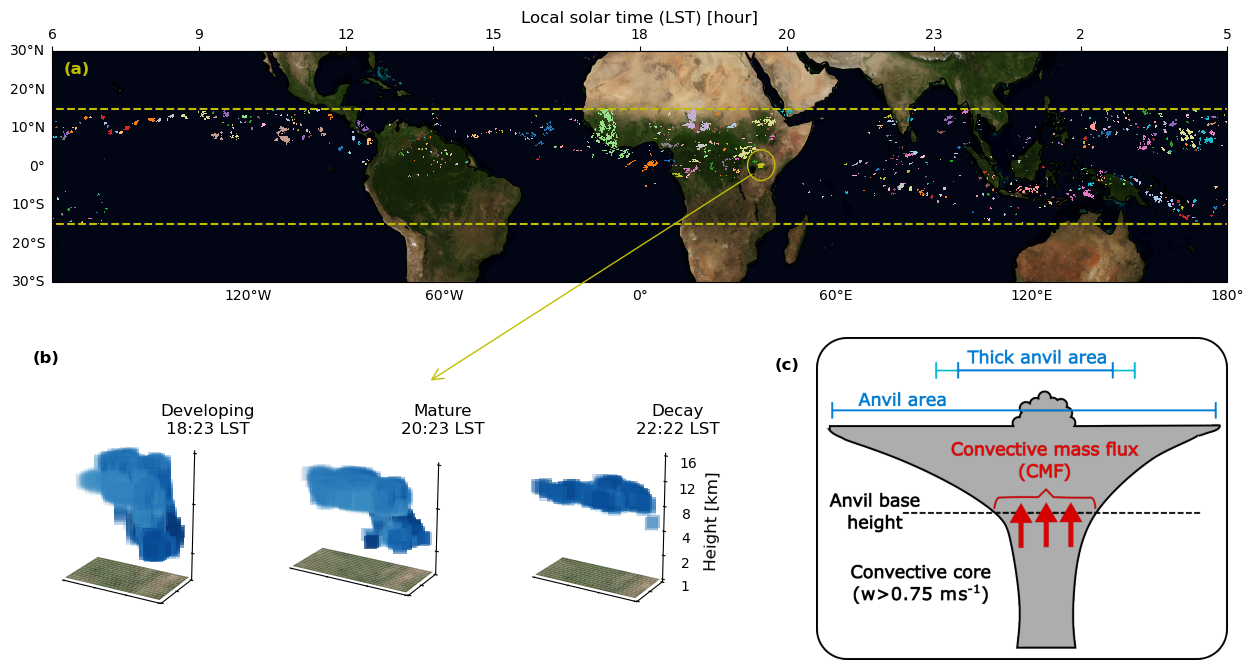

In [10]:
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

fs = 12

tstr = pdata.sel(time=utc).time.dt.strftime('%Y%m%dT%H%M').item()
fpath = paperdir / f'fig01_{tstr}.{ext}'
    
# --- layout ---
proj = ccrs.Robinson()
nlon = 360
nlat = 60
scale = 0.05
fig, ax = plt.subplots(figsize=(nlon*scale, nlat*scale), subplot_kw=dict(projection=proj))

## 1. plot tropics
make_map(ax, pdata, utc, cmap)
ax.text(0.01, .9, '(a)', fontsize=fs, weight='bold', c='y', transform=ax.transAxes)

## 2. show example
t1 = datetime.datetime.strptime(utc, '%Y%m%d%H%M')
t0 = t1 - datetime.timedelta(hours=2)
t2 = t1 + datetime.timedelta(hours=2)

dws = [0,0,0]
dcs = [1,1,1]
name = ("Developing", "Mature", "Decay")
for j, t in enumerate((t0,t1,t2)):
    # axes
    pc = ccrs.PlateCarree()
    bbox = ax.get_position()
    inset_w = bbox.width / 3 * 0.6
    inset_h = bbox.height * .8
    inset_x = bbox.x0 + inset_w * j - .025
    inset_y = bbox.y0 - 1.1
    inset_ax = fig.add_axes([inset_x, inset_y, inset_w, inset_h], projection='3d')
    if not j:
        inset_ax.text2D(0, 1.35, '(b)', fontsize=fs, weight='bold', c='k', transform=inset_ax.transAxes)
    # data
    sidx = 3876
    d = ice.sel(time=t).expand_dims('time')
    mask = d.where(d == sidx).dropna('lat', how='all').dropna('lon', how='all')
    make_example(inset_ax, mask, t, show_dc=dcs[j], show_dw=dws[j], zaxis=j==2, haxis=0, name=name[j])

# circle
radius = 4
clon = mask.lon.mean()
clat = mask.lat.mean()
ax.add_patch(Circle((clon, clat), radius=radius, transform=pc, fill=False, ec='y', lw=1, zorder=20,))

# line
pt_data = proj.transform_point(clon-radius/2, clat-radius/2, pc)
pt_disp = ax.transData.transform(pt_data)
pt_fig = fig.transFigure.inverted().transform(pt_disp)
inset_pos = inset_ax.get_position()
x2 = bbox.x0 + inset_w * 1.6
y2 = inset_pos.y1 + .15
# fig.add_artist(Line2D([pt_fig[0], x2],[pt_fig[1], y2], transform=fig.transFigure, color='y', lw=1, zorder=15,))
fig.add_artist(mpl.patches.FancyArrowPatch((pt_fig[0], pt_fig[1]),(x2, y2), transform=fig.transFigure, arrowstyle='->', color='y', mutation_scale=20, zorder=15,))

## 3. show method

img = plt.imread("/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/fig01_diagram.png")

bbox = ax.get_position()
inset_w = bbox.width * 0.35
inset_h = bbox.height * 1.5
inset_x = bbox.x1 - inset_w
inset_y = bbox.y0 - 1.3
ax_img = fig.add_axes([inset_x, inset_y, inset_w, inset_h])
ax_img.imshow(img)
ax_img.axis('off')
ax_img.text(-.1, .9, '(c)', fontsize=fs, weight='bold', c='k', transform=ax_img.transAxes)

## 4. SAVE
fig.savefig(paperdir / f'fig01.{ext}', dpi=dpi, bbox_inches='tight')

#### MAP

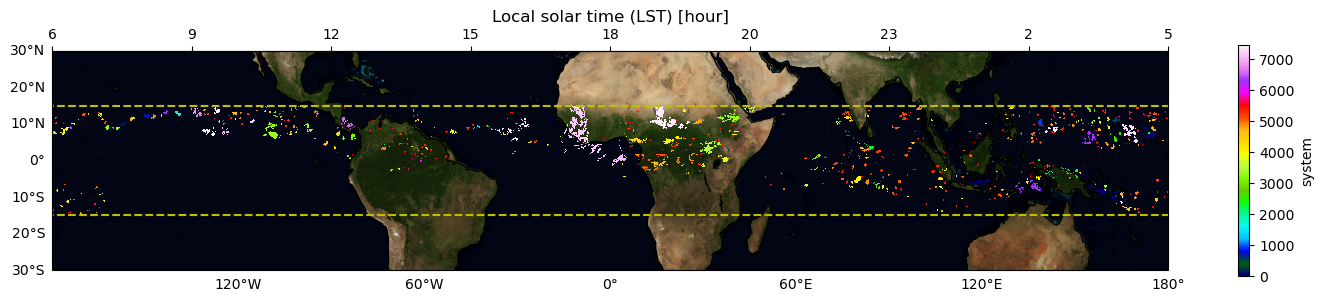

In [11]:
fs = 12
cmap = 'gist_ncar'

tstr = pdata.sel(time=utc).time.dt.strftime('%Y%m%dT%H%M').item()
fpath = paperdir / f'fig01_{tstr}.{ext}'
    
# --- layout ---
proj = ccrs.Robinson()
nlon = 360
nlat = 60
scale = 0.05
fig, ax = plt.subplots(figsize=(nlon*scale, nlat*scale), subplot_kw=dict(projection=proj))

# plot tropics
plotting.plot_masks(ax, pdata, utc, cmap=cmap, vmin=0, vmax=vmax)
ax.set_extent((0,360,-30,30), crs=ccrs.PlateCarree())
ax.plot([0,360],[15,15],ls='--',c='y',transform=ccrs.PlateCarree())
ax.plot([0,360],[-15,-15],ls='--',c='y',transform=ccrs.PlateCarree())
ax.coastlines()
plotting.plot_surface(ax)
ax.set(title=None)
ax.set_xlabel('Longitude', fontsize=fs)

# add solar time
utc_dt = datetime.datetime.strptime(utc, '%Y%m%d%H%M')
utc_hour = utc_dt.hour + utc_dt.minute / 60
pc = ccrs.PlateCarree()
clat = 0

def solar_time(xproj):
    x = np.atleast_1d(np.asarray(xproj, dtype=float))
    lons = pc.transform_points(proj, x, np.full_like(x, clat))[:, 0]
    return np.array([(utc_dt + datetime.timedelta(hours=lon / 15.0)).hour for lon in lons])
# def inverse(lst):
#     h = np.atleast_1d(np.asarray(lst, dtype=float))
#     lon = (h - utc_hour) * 15.0
#     return (proj.transform_points(pc, lon, np.full_like(lon, clat))[:, 0]).round(2)

top_ax = ax.secondary_xaxis('top', functions=(lambda x:x, lambda x:x))
top_ax.set_xlabel('Local solar time (LST) [hour]', fontsize=fs)
xticks = np.linspace(*ax.get_xlim(), 9)
xlables = np.nan_to_num(solar_time(xticks).round(0).astype(int), nan=0)
top_ax.set_xticks(xticks, xlables)

# save
fig.savefig(fpath, dpi=dpi, bbox_inches='tight')

[Text(0.5, 1.0, '')]

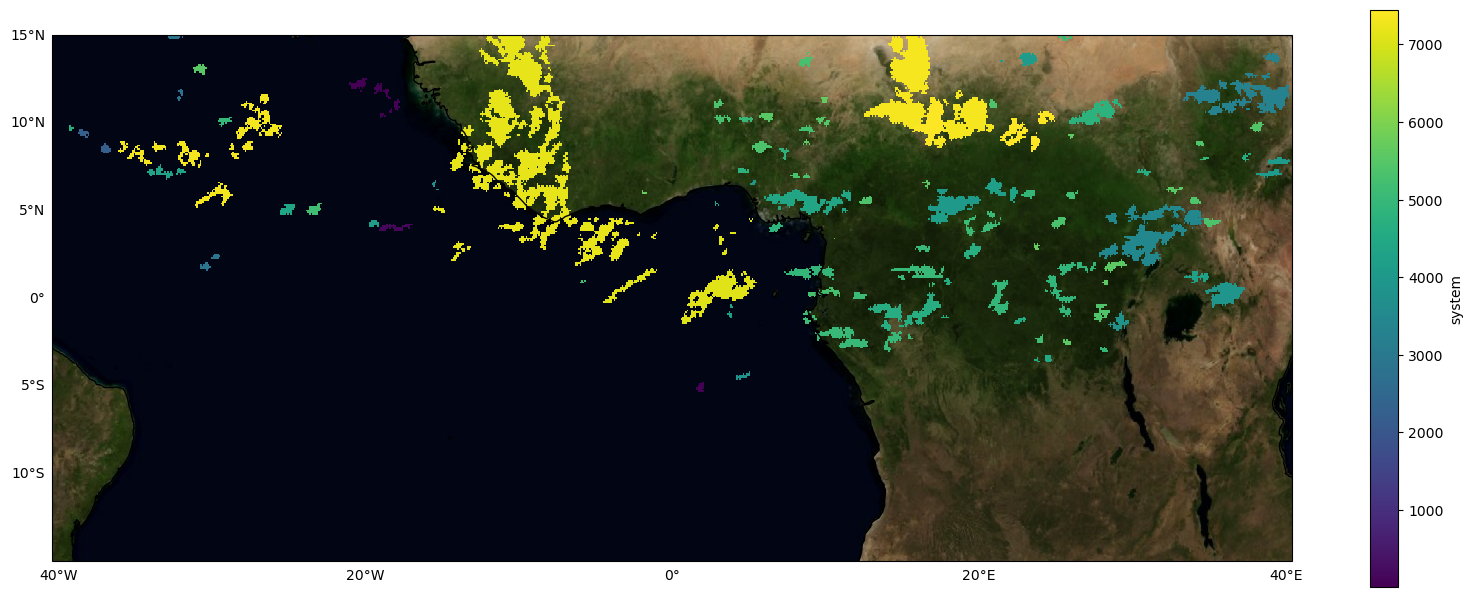

In [12]:
# --- search for expample cloud

extent = (-40,40,-15,15)

# --- layout ---
proj = ccrs.Robinson()
nlon = extent[1] - extent[0]
nlat = extent[3] - extent[2]
scale = 0.25
fig, ax = plt.subplots(figsize=(nlon*scale, nlat*scale), subplot_kw=dict(projection=proj))

# plot tropics
d = pdata.sel(lon=slice(extent[0], extent[1]), lat=slice(extent[2], extent[3]))
plotting.plot_masks(ax, d, utc, cmap='viridis', vmin=d.min(), vmax=d.max())
ax.set_extent(extent, crs=ccrs.PlateCarree())
ax.coastlines()
plotting.plot_surface(ax)
ax.set(title=None)

(90.0, 40.0)

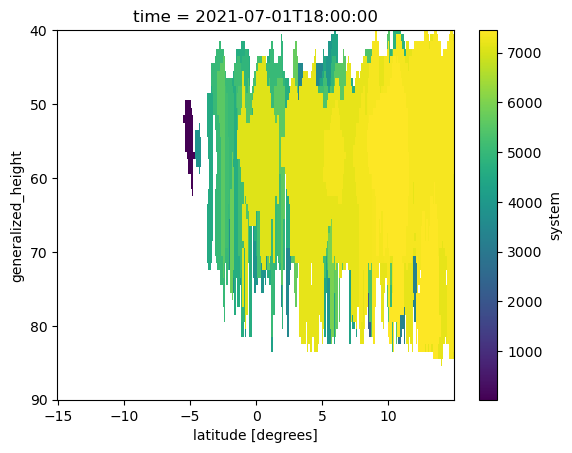

In [13]:
d.max('lon').plot()
plt.ylim(90,40)

<xarray.DataArray 'system' ()> Size: 8B
array(0.)


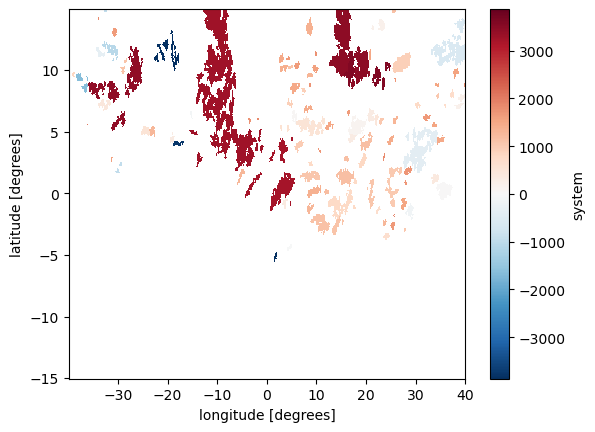

In [14]:
# sidx = 5516
# sidx = 4859
sidx = 3876 # anvil only
print(np.abs(d-sidx).min())
(d-sidx).min(('time','level_full')).plot()

#### 3D SNAPSHOT

In [15]:
def prep_example_data(mask):
    # load
    variables = ['cli', 'clw', 'pfull', 'zg', 'zghalf', 'wa_phy']
    data = g3d.utils.data_tools.load_corresponding_data(mask, None, variables=variables)
    data = g3d.utils.data_tools.preprocess_for_tobac(data)
    data['lat'] = data.lat.round(2)
    data['lon'] = data.lon.round(2)
    mask['lat'] = mask.lat.round(2)
    mask['lon'] = mask.lon.round(2)
    data['condensate'] = data.cli + data.clw
    # prep
    z_pfull = data.pfull.mean(('lat','lon','time'))
    z_zg = data.zg.mean(('lat','lon')) / 1000
    dw = data.where(data > 1).where(mask > 0)
    dc = data.where(data > 1e-5).where(mask > 0)
    dw = dw.assign_coords({'zg':z_zg}).compute()
    dc = dc.assign_coords({'zg':z_zg}).compute()
    mask = mask.assign_coords({'zg':z_zg})
    return mask, dc, dw
    
def make_proj(ax, data, coord='level_full', levels=[0.5], params=dict(offset=-1, cmap='viridis')):
    if coord=='level_full':
        m = data.sel(time=t).max('level_full')
        X, Y = np.meshgrid(m.lon, m.lat)
        ax.contour(X, Y, (m.fillna(0)).astype(int), levels, zdir='z', **params)
    if coord=='lon':
        m = data.sel(time=t).max('lon')
        Y, Z = np.meshgrid(m.lat, m.zg)
        ax.contour((m.fillna(0)).astype(int), Y, Z, levels, zdir='x', **params)
    if coord=='lat':
        m = data.sel(time=t).max('lat')
        X, Z = np.meshgrid(m.lon, m.zg)
        ax.contour(X, (m.fillna(0)).astype(int), Z, levels, zdir='y', **params)
    return ax

def make_example(ax, mask, utc):
    mask, dc, dw = prep_example_data(mask)

    # local time
    t = pd.to_datetime(utc)
    def solar_time(lon):
        return (t + datetime.timedelta(hours=lon / 15.0))
    t_local = solar_time(d.lon.mean().item())
    
    # plot condensate
    # norm = plt.Normalize(vmin=1e-5, vmax=1e-3)
    norm = mpl.colors.LogNorm()
    cmap = plt.get_cmap('Blues')
    ax = plotting.plot_surface3d(ax, dc, z=90, params=dict(alpha=.8))
    
    # scatter size
    p0 = ax.transData.transform((float(dc.lon.min()), float(dc.lat.min())))
    p1 = ax.transData.transform((float(dc.lon.min() + 0.1), float(dc.lat.min() + 0.1)))
    dx_pix = abs(p1[0] - p0[0])
    size = (dx_pix * 72.0 / dpi)
    size = 400
    
    # scatter
    ax = plotting.plot_scatter(ax, dc.sel(time=t), hue='condensate', params=dict(s=size, norm=norm, marker='s'), cmap='Blues', f=0)
    ax = plotting.plot_scatter(ax, dw.sel(time=t), hue='wa_phy', params=dict(s=size, norm=None, marker='s'), cmap='Reds', f=0)
    date_str = d.time.dt.strftime('%b-%d').values
    ax.view_init(20, None)
    ax = plotting.modify_axis(ax, dc, fsize=fs)
    
    # label z axis
    zg = data.zg.mean(('lat','lon')).values / 1000
    ax.set_zticks(data.level_full[::10])
    ax.set_zticklabels(zg[::10].astype(int))  # Equivalent to ax.zaxis.set_ticks(zg)
    ax.set_zlabel("Height [km]", fontsize=12)
    
    # stretch height
    xrange = dc.lon.max() - dc.lon.min()
    yrange = dc.lat.max() - dc.lat.min()
    zrange = dc.zg.max() - dc.zg.min()
    ax.set_box_aspect((xrange, yrange, zrange*0.2))
    
    # horizontal ticks
    xticks = np.linspace(float(dc.lon.min()), float(dc.lon.max()), 4).round(1)
    yticks = np.linspace(float(dc.lat.min()), float(dc.lat.max()), 3).round(1)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    
    # title
    tstr = f"{t_local.strftime('%H:%M')} LST"
    ax.set_title(tstr, fontsize=fs)
    ax.set_title(None)
    ax.text2D(0.95, .9, tstr, ha='center', va='top', transform=ax.transAxes, fontsize=fs, weight='bold')

In [16]:
mask = d.where(d == sidx).dropna('lat', how='all').dropna('lon', how='all')

In [17]:
# get corresponding data

variables = ['cli', 'clw', 'pfull', 'zg', 'zghalf', 'wa_phy']
data = g3d.utils.data_tools.load_corresponding_data(mask, None, variables=variables)
data = g3d.utils.data_tools.preprocess_for_tobac(data)
data['lat'] = data.lat.round(2)
data['lon'] = data.lon.round(2)
mask['lat'] = mask.lat.round(2)
mask['lon'] = mask.lon.round(2)
data['condensate'] = data.cli + data.clw

INFO:root:Region to regrid: (34.09999999998783, 37.59999999998764, -0.5000000000000515, 1.0999999999999432)


In [18]:
# get heights
z_pfull = data.pfull.mean(('lat','lon','time'))
z_zg = data.zg.mean(('lat','lon')) / 1000

# data preprocessing
# cmask = ds.u_tracks.sel(lat=mask.lat, lon=mask.lon, time=mask.time)
dw = data.where(data > 1).where(mask > 0)
dc = data.where(data > 1e-5).where(mask > 0)
dw = dw.assign_coords({'zg':z_zg}).compute()
dc = dc.assign_coords({'zg':z_zg}).compute()
mask = mask.assign_coords({'zg':z_zg})

def make_proj(ax, data, coord='level_full', levels=[0.5], params=dict(offset=-1, cmap='viridis')):
    if coord=='level_full':
        m = data.sel(time=t).max('level_full')
        X, Y = np.meshgrid(m.lon, m.lat)
        ax.contour(X, Y, (m.fillna(0)).astype(int), levels, zdir='z', **params)
    if coord=='lon':
        m = data.sel(time=t).max('lon')
        Y, Z = np.meshgrid(m.lat, m.zg)
        ax.contour((m.fillna(0)).astype(int), Y, Z, levels, zdir='x', **params)
    if coord=='lat':
        m = data.sel(time=t).max('lat')
        X, Z = np.meshgrid(m.lon, m.zg)
        ax.contour(X, (m.fillna(0)).astype(int), Z, levels, zdir='y', **params)
    return ax

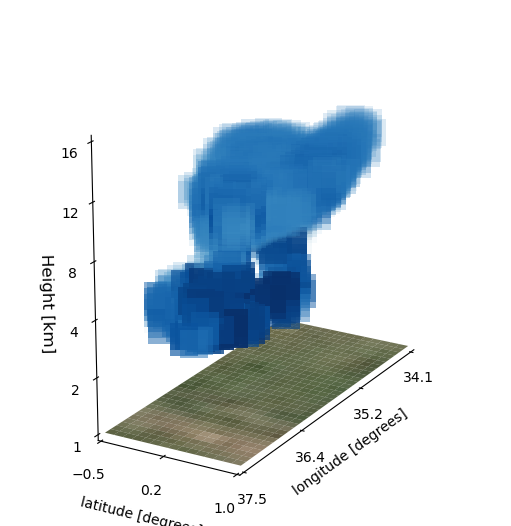

In [19]:
# view
fs = 12

# local time
t = pd.to_datetime(utc)
def solar_time(lon):
    return (t + datetime.timedelta(hours=lon / 15.0))
t_local = solar_time(d.lon.mean().item())

# fig
fig, ax = plt.subplots(1,1,figsize=(5,8), subplot_kw=dict(projection='3d'), constrained_layout=True)
cmap = plt.get_cmap('Blues')

# plot condensate
# norm = plt.Normalize(vmin=1e-5, vmax=1e-3)
norm = mpl.colors.LogNorm()
# norm = None
ax = plotting.plot_surface3d(ax, dc, z=90, params=dict(alpha=.8))

# scatter size
p0 = ax.transData.transform((float(dc.lon.min()), float(dc.lat.min())))
p1 = ax.transData.transform((float(dc.lon.min() + 0.1), float(dc.lat.min() + 0.1)))
dx_pix = abs(p1[0] - p0[0])
size = (dx_pix * 72.0 / dpi)
size = 400

# scatter
ax = plotting.plot_scatter(ax, dc.sel(time=t), hue='condensate', params=dict(s=size, norm=norm, marker='s'), cmap='Blues', f=0)
ax = plotting.plot_scatter(ax, dw.sel(time=t), hue='wa_phy', params=dict(s=size, norm=None, marker='s'), cmap='Reds', f=0)
date_str = d.time.dt.strftime('%b-%d').values
ax.view_init(20, 30)
ax = plotting.modify_axis(ax, dc, fsize=fs)

# label z axis
zg = data.zg.mean(('lat','lon')).values / 1000
ax.set_zticks(data.level_full[::10])
ax.set_zticklabels(zg[::10].astype(int))  # Equivalent to ax.zaxis.set_ticks(zg)
ax.set_zlabel("Height [km]", fontsize=12, rotation=90)

# stretch height
xrange = dc.lon.max() - dc.lon.min()
yrange = dc.lat.max() - dc.lat.min()
zrange = dc.zg.max() - dc.zg.min()
ax.set_box_aspect((xrange, yrange, zrange*0.2))

# horizontal ticks
xticks = np.linspace(float(dc.lon.min()), float(dc.lon.max()), 4).round(1)
yticks = np.linspace(float(dc.lat.min()), float(dc.lat.max()), 3).round(1)
ax.set_xticks(xticks)
ax.set_yticks(yticks)

# title
# tstr = f"{t_local.strftime('%H:%M')} LST"
# ax.set_title(tstr, fontsize=fs)
ax.set_title(None)
# ax.text2D(0.95, .9, tstr, ha='center', va='top', transform=ax.transAxes, fontsize=fs, weight='bold')

fig.savefig(paperdir / f'fig01_inset-{sidx}.{ext}', bbox_inches='tight', pad_inches=0.38)